# 원본 감사

학습20대의 센서·고장·TTF를 전수 감사한 결과입니다. 시각의 물리 단위는 미확정이며 원본을 변경하지 않았습니다.

In [1]:
from pathlib import Path
import os, json, sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert ROOT.name == 'PHM2018-Project-V2'
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT / 'outputs/matplotlib')
import polars as pl
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
figdir = ROOT / 'reports/figures'
figdir.mkdir(parents=True, exist_ok=True)
load = lambda name: json.loads((ROOT / 'outputs' / name).read_text(encoding='utf-8'))


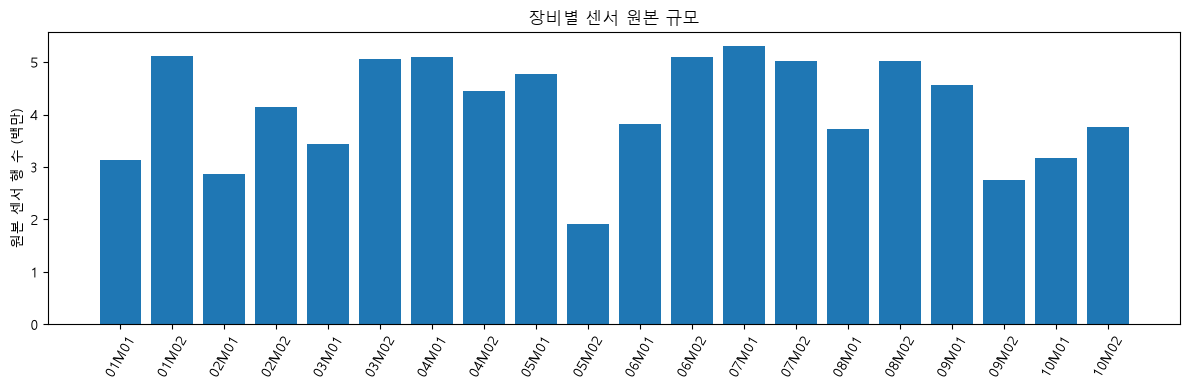

전체 행 수: 82,189,440
태그 제외 TTF 불일치: 0


In [2]:
audit = load('audit_summary.json')
fig, ax = plt.subplots(figsize=(12,4))
ax.bar([a['tool'] for a in audit], [a['raw_rows']/1e6 for a in audit])
ax.set(ylabel='원본 센서 행 수 (백만)', title='장비별 센서 원본 규모')
ax.tick_params(axis='x', rotation=60)
fig.tight_layout(); fig.savefig(figdir / '01_raw_rows.png', dpi=130); plt.show()
print('전체 행 수:', f"{sum(a['raw_rows'] for a in audit):,}")
print('태그 제외 TTF 불일치:', sum(v['exclude_tag_mismatch'] for a in audit for v in a['ttf'].values()))

## 그래프 해석과 한계

막대 높이는 장비별 기록량 차이입니다. 기록량이나 Stage=0의 존재만으로 정상/정비 상태를 확정하지 않습니다. 중복·공백·결측의 상세 원인은 장비별 감사 JSON/Parquet에 보존했습니다.

상세 결과는 `reports/`의 한국어 보고서와 `outputs/`의 수치 파일을 참조하세요.